# 1. Séparation de sources simulées : Infomax, FastICA et SGD-ICA

Ce notebook compare plusieurs algorithmes d'ICA sur **les mêmes sources et les mêmes matrices de mélange** (20 tirages par scénario). Le code des algorithmes est dans `src/ica_stoch/` ; le notebook ne contient que l'expérience et son analyse.

**Métrique** : indice d'Amari entre la vraie matrice de mélange $A$ et la matrice de séparation estimée $W$ (0 = séparation parfaite).

In [ ]:
# Configuration : rend le module ica_stoch importable, en local comme sur Google Colab
import importlib.util, subprocess, sys
from pathlib import Path

REPO = "ICA-Stochastique-2026"
if importlib.util.find_spec("ica_stoch") is None:
    candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / REPO, Path("/content") / REPO]
    root = next((p for p in candidates if (p / "src" / "ica_stoch").is_dir()), None)
    if root is None:  # ni dépôt local ni zip décompressé : on clone le dépôt GitHub
        subprocess.run(["git", "clone", "-q", f"https://github.com/elikosarah/{REPO}.git"], check=True)
        root = Path(REPO).resolve()
    sys.path.insert(0, str(root / "src"))

for pkg in ("mne", "nilearn"):  # absents par défaut sur Colab
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

In [1]:
import warnings
import matplotlib.pyplot as plt
import pandas as pd

from ica_stoch import SCENARIOS, SGDICA, amari_index, grid_search_sgd, make_mixing, make_sources, run_benchmark
from ica_stoch.data import excess_kurtosis
from ica_stoch.plots import plot_amari_comparison, plot_convergence, plot_grid_search, plot_separation

warnings.filterwarnings("ignore")
N_RUNS = 20

## Les trois scénarios

L'ICA exploite la non-gaussianité. Le **signe du kurtosis** (négatif : sub-gaussienne, positif : super-gaussienne) détermine quelle non-linéarité convient : c'est le fil conducteur des résultats.

In [2]:
rows = []
for k, sc in SCENARIOS.items():
    S, _ = make_sources(k)
    rows.append({"jeu": sc.name, "sources": sc.description, "kurtosis": excess_kurtosis(S).round(2).tolist()})
pd.DataFrame(rows)

,jeu,sources,kurtosis
0,Jeu 1 — mixte,"sinusoïde, signal carré, Laplace (sub- et supe...","[-1.5, -2.0, 2.71]"
1,Jeu 2 — super-gaussien,"sinusoïde, exponentielle, Laplace","[-1.5, 6.06, 2.97]"
2,Jeu 3 — sub-gaussien,"sinusoïde, signal carré, uniforme","[-1.5, -2.0, -1.23]"


Amari = 0.0137, types estimés = [-1.  1. -1.]  (+1 super, -1 sub)


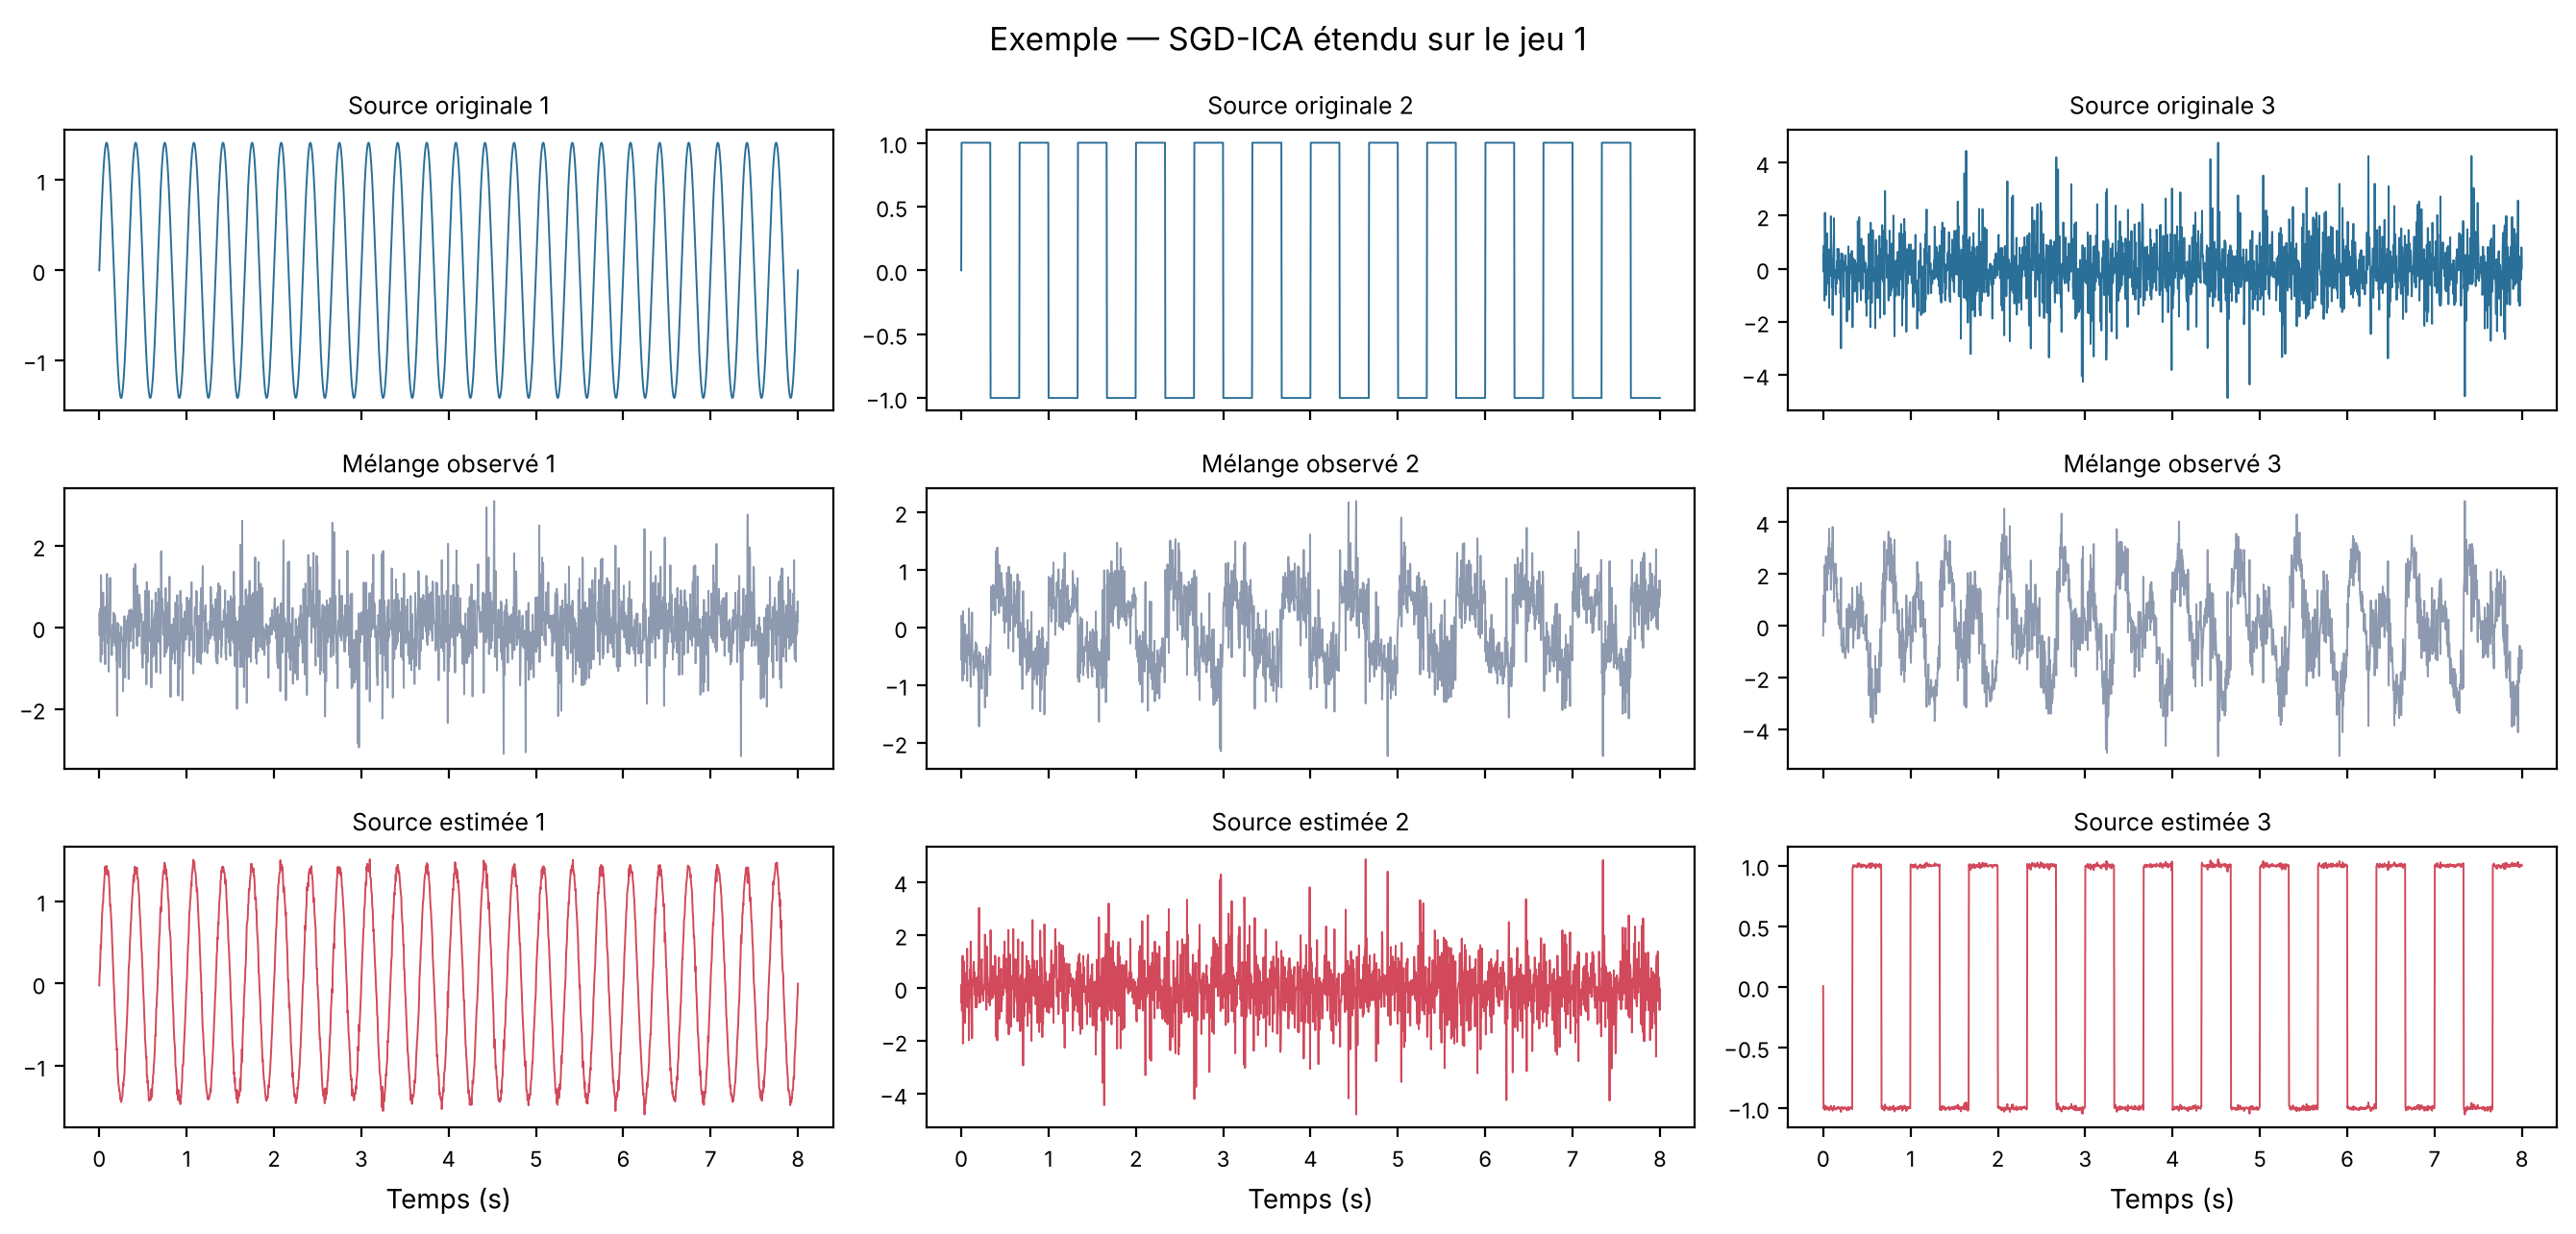

In [3]:
S, t = make_sources(1)
A = make_mixing(3, seed=0)
ica = SGDICA(random_state=0).fit(A @ S)
print(f"Amari = {amari_index(A, ica.components_):.4f}, types estimés = {ica.signs_}  (+1 super, -1 sub)")
plot_separation(t, S, A @ S, ica.transform(A @ S), "Exemple — SGD-ICA étendu sur le jeu 1");

## Réglage du pas de SGD-ICA

Pas de Robbins-Monro $\eta_e = \eta_0 / (1+e)$ par époque. Recherche de $\eta_0$ sur 5 tirages par valeur et par jeu.

In [4]:
lrs = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
grid = pd.concat([grid_search_sgd(k, lrs, n_runs=5).assign(jeu=k) for k in SCENARIOS], ignore_index=True)
best_lr = float(grid.groupby("learning_rate")["amari_mean"].mean().idxmin())
print(f"Pas retenu : {best_lr}")
grid.pivot(index="learning_rate", columns="jeu", values="amari_mean").round(4)

Pas retenu : 0.005


jeu,1,2,3
learning_rate,,,
0.005,0.0125,0.0051,0.0081
0.010,0.0120,0.0051,0.0086
0.020,0.0132,0.0045,0.0091
0.050,0.0127,0.0088,0.0096
0.100,0.0151,0.0205,0.0093
0.200,0.0294,0.0474,0.0138
0.500,0.0568,0.1080,0.0136


## Comparaison sur 20 tirages

Les variantes « super » et « sub » de SGD-ICA fixent la non-linéarité ; la variante **étendue** choisit le signe de chaque composante à chaque époque (Infomax étendu, Lee et al. 1999). La dernière utilise le **gradient naturel** (Amari, 1998), restreint aux rotations.

In [5]:
sgd = dict(learning_rate=best_lr, n_epochs=50)
CONFIGS = [
    ("Infomax (MNE, tanh)", "infomax", {}),
    ("FastICA (log cosh)", "fastica", {}),
    ("SGD, hyp. super-gauss.", "sgd", dict(nonlinearity="super", natural_gradient=False, **sgd)),
    ("SGD, hyp. sub-gauss.", "sgd", dict(nonlinearity="sub", natural_gradient=False, **sgd)),
    ("SGD étendu", "sgd", dict(nonlinearity="extended", natural_gradient=False, **sgd)),
    ("SGD étendu, grad. naturel", "sgd", dict(nonlinearity="extended", natural_gradient=True, **sgd)),
]
results = [run_benchmark(m, k, n_runs=N_RUNS, label=lab, **p) for k in SCENARIOS for lab, m, p in CONFIGS]

table = pd.DataFrame([{"méthode": r.label, "jeu": r.scenario, "amari": f"{r.mean:.4f} ± {r.std:.4f}"} for r in results])
table.pivot(index="méthode", columns="jeu", values="amari").loc[[c[0] for c in CONFIGS]]

jeu,1,2,3
méthode,,,
"Infomax (MNE, tanh)",0.3827 ± 0.0571,0.0994 ± 0.0639,0.6647 ± 0.0203
FastICA (log cosh),0.0124 ± 0.0000,0.0046 ± 0.0000,0.0079 ± 0.0000
"SGD, hyp. super-gauss.",0.4544 ± 0.0764,0.2723 ± 0.0515,0.6774 ± 0.0234
"SGD, hyp. sub-gauss.",0.1450 ± 0.0811,0.4944 ± 0.0828,0.0080 ± 0.0002
SGD étendu,0.0130 ± 0.0014,0.0053 ± 0.0016,0.0080 ± 0.0002
"SGD étendu, grad. naturel",0.0124 ± 0.0008,0.0049 ± 0.0013,0.0082 ± 0.0002


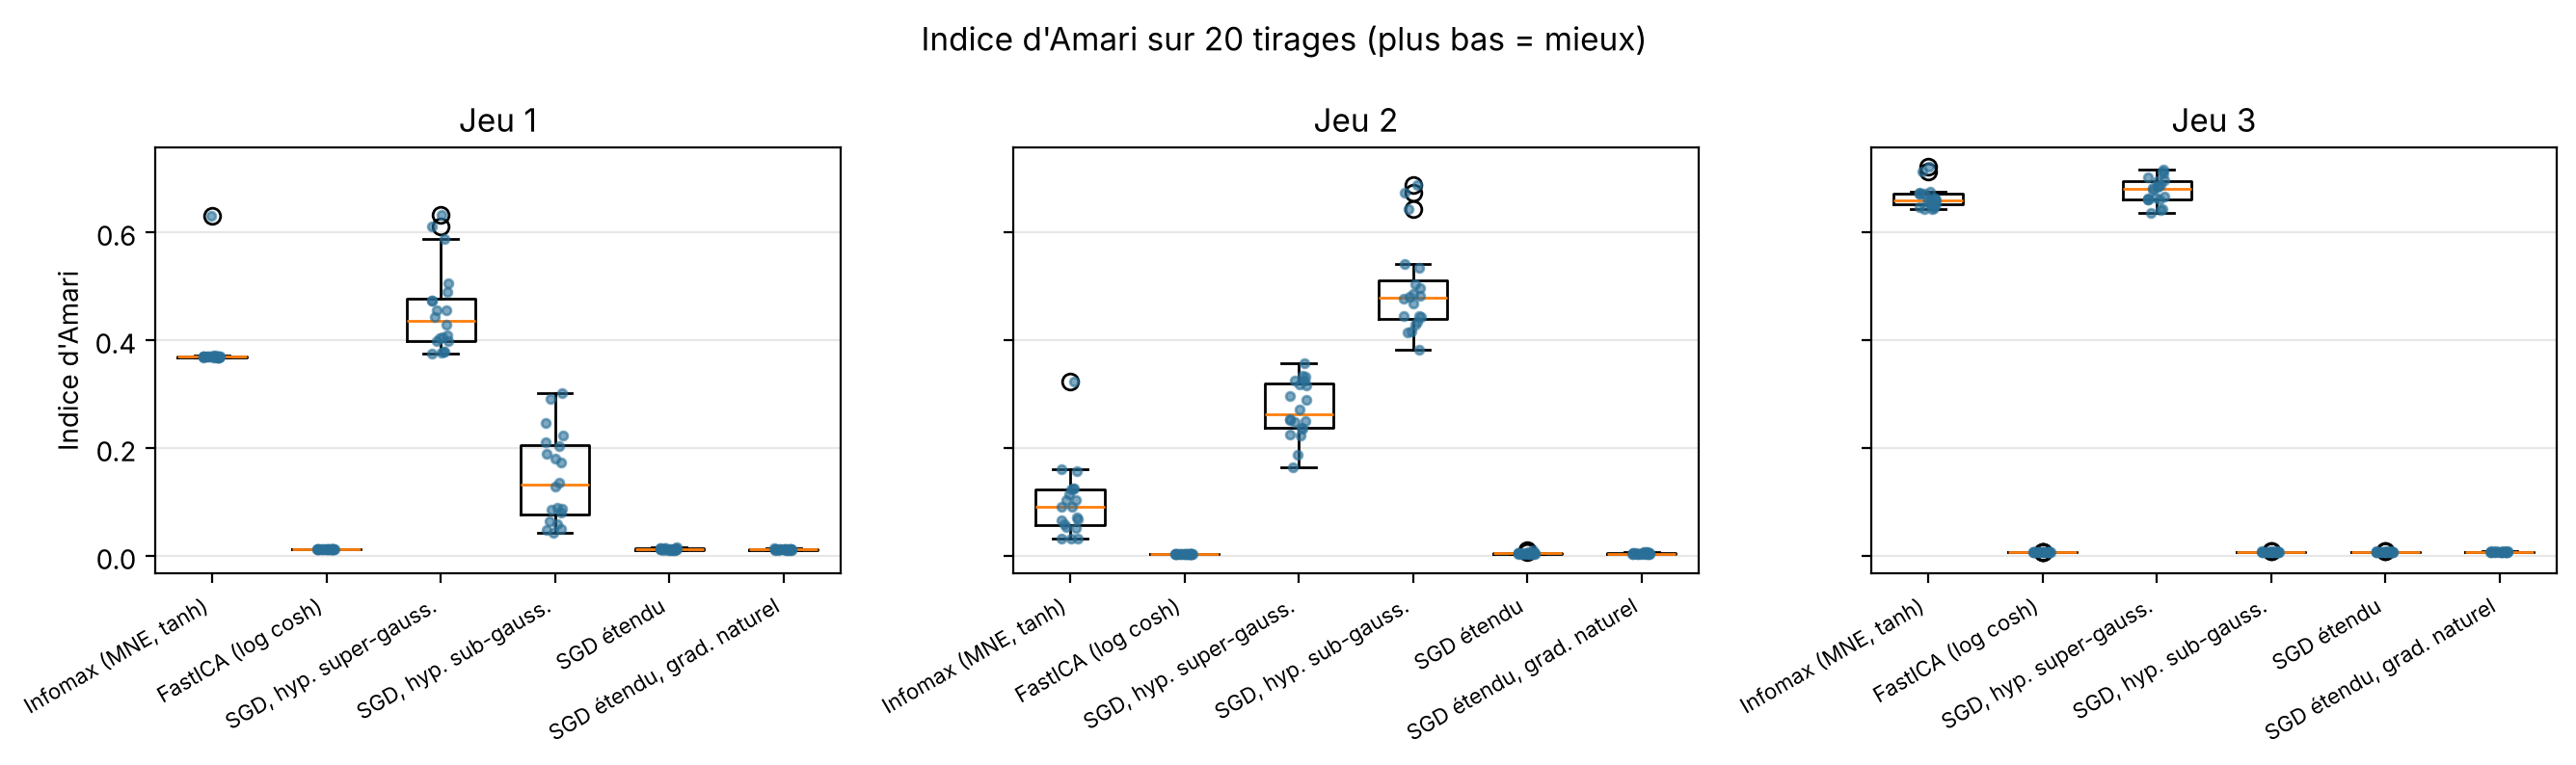

In [6]:
plot_amari_comparison(results);

## Lecture des résultats

- **Infomax avec `tanh` fixe** et **SGD avec hypothèse super-gaussienne** se comportent de la même façon : bons quand les sources sont super-gaussiennes, en échec sur le jeu 3 (sources toutes sub-gaussiennes, Amari ≈ 0,67). L'hypothèse sur la densité des sources n'est pas un détail : si elle est fausse, l'algorithme converge vers une mauvaise solution.
- Symétriquement, l'**hypothèse sub-gaussienne** réussit sur le jeu 3 et échoue sur le jeu 2.
- La version **étendue** estime le type de chaque source et atteint le niveau de FastICA sur les trois jeux (Amari ≈ 0,005 à 0,013).
- Le **gradient naturel** donne la même précision sans inverser $W$ à chaque pas.

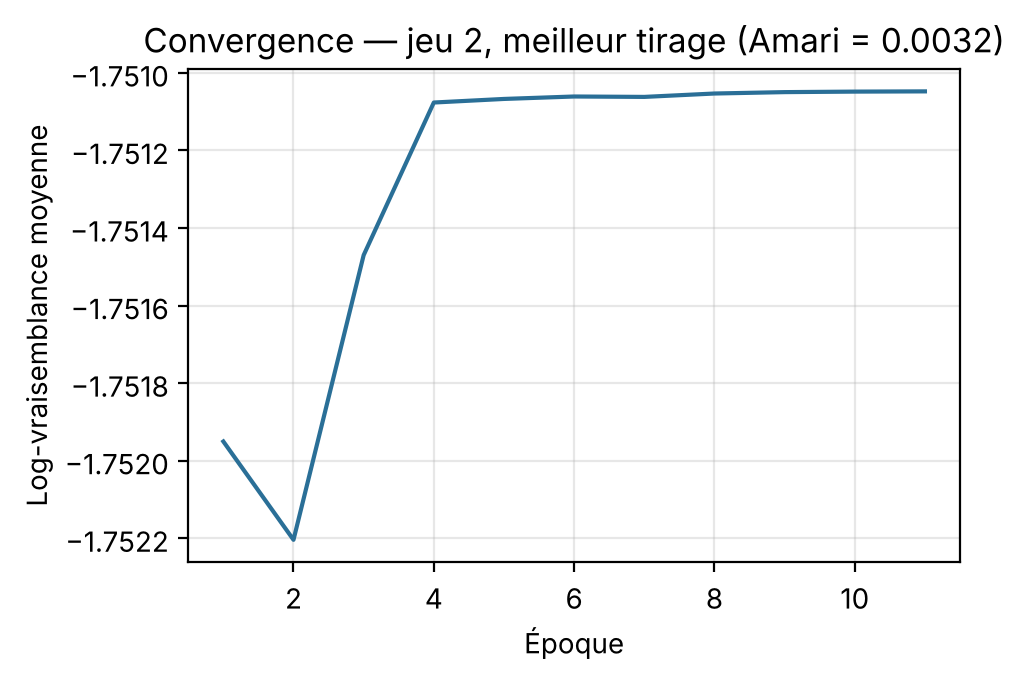

In [7]:
best = next(r for r in results if r.scenario == 2 and r.label == "SGD étendu, grad. naturel").best_run
plot_convergence(best["objective"], f"Convergence — jeu 2, meilleur tirage (Amari = {best['amari']:.4f})");